# Final model selection and held-out evaluation

Selection uses saved VALIDATION RMSE only, across the six completed configurations. Exact RMSE ties use alphabetical model name; MAE and R-squared are supporting metrics. The selected configuration is written to `phase11_selection_lock.json` before TEST access. Under current artifacts, Tuned XGBoost wins because it has the lowest validation RMSE.

TRAIN + VALIDATION are combined chronologically to use all development observations after model choice is fixed. The selected model is fitted once with its unchanged Phase 10 parameters, no scaler, no early stopping and no test inputs. Only then does section C of `run_phase11` first open the test file (checksum followed by CSV loading). Phase 6 previously inspected test distribution for splitting; it was reserved from model development and tuning through Phase 10.

Run `.venv/Scripts/python.exe ml/src/evaluate_final_model.py` first, then its `--verify-reproducibility` replay. This notebook uses the shared saved-result loader; it does not create a second evaluation pipeline or refit a model.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'ml/src/evaluate_final_model.py').is_file())
sys.path.insert(0, str(PROJECT_ROOT))
from ml.src.evaluate_final_model import load_saved_evaluation, read_json, REPLAY_PATH
report, predictions = load_saved_evaluation()
print(report['selection_statement'])
print('Final model:', report['final_model_name'])
print('Exact selected parameters:', report['selected_hyperparameters'])
display(pd.DataFrame(report['validation_ranking']))
print('TRAIN / VALIDATION / development / TEST rows:', *[report[k] for k in ['train_rows', 'validation_rows', 'development_rows', 'test_rows']])
print('Development:', report['development_start_timestamp'], 'through', report['development_end_timestamp'])
print('TEST:', report['test_start_timestamp'], 'through', report['test_end_timestamp'])
assert report['expected_tuned_xgboost_selected']
assert report['feature_count'] == 42
assert report['development_rows'] == report['train_rows'] + report['validation_rows']
assert 'date' not in report['feature_columns'] and report['target'] not in report['feature_columns']
assert 'Appliances' in report['feature_columns']
assert len(predictions) == report['test_rows']

Final model selection was completed before accessing the held-out test set.
Final model: Tuned XGBoost
Exact selected parameters: {'colsample_bytree': 1.0, 'learning_rate': 0.03, 'max_depth': 3, 'min_child_weight': 5, 'n_estimators': 100, 'n_jobs': 1, 'objective': 'reg:squarederror', 'random_state': 42, 'subsample': 1.0, 'tree_method': 'hist', 'verbosity': 0}


,mae,model,r2,rmse
0,25.493202,Tuned XGBoost,0.589816,57.625638
1,27.025294,Linear Regression,0.564956,59.346237
2,33.030369,Tuned Random Forest,0.486059,64.503521
3,25.920256,Persistence Baseline,0.465273,65.794972
4,54.392578,Untuned XGBoost,-0.013412,90.577337
5,53.004521,Untuned Random Forest,-0.255527,100.818362


TRAIN / VALIDATION / development / TEST rows: 13108 2809 15917 2809
Development: 2016-01-18 17:00:00 through 2016-05-08 05:40:00
TEST: 2016-05-08 05:50:00 through 2016-05-27 17:50:00


## Final full-test metrics and descriptive generalization

All test observations contribute to the final metrics. Validation describes the earlier TRAIN-only fit; TEST describes the fixed configuration refitted on TRAIN + VALIDATION, over a later period. Their difference is descriptive, not a controlled estimate of a refitting effect. No decisions are made using test performance.

In [2]:
comparison = pd.DataFrame({'Validation (TRAIN fit)': report['selected_validation_metrics'], 'Held-out TEST (development refit)': {k: report['test_' + k] for k in ['mae', 'rmse', 'r2']}}).T
display(comparison)
print(report['generalization_description'])
print('TEST minus validation RMSE:', report['test_rmse_minus_validation_rmse'])
print('RMSE change (%):', report['test_rmse_change_percent'])

,mae,r2,rmse
Validation (TRAIN fit),25.493202,0.589816,57.625638
Held-out TEST (development refit),25.891125,0.582013,59.117011


Test RMSE increased
TEST minus validation RMSE: 1.491373846241295
RMSE change (%): 2.5880387754270266


## Actual versus predicted: first seven contiguous test days

The window begins at the first test forecast-origin timestamp and ends exclusively seven days later. This deterministic subsection is for readability; metrics above use the full test period. The target is Appliances energy ten minutes after the plotted origin, in Wh.

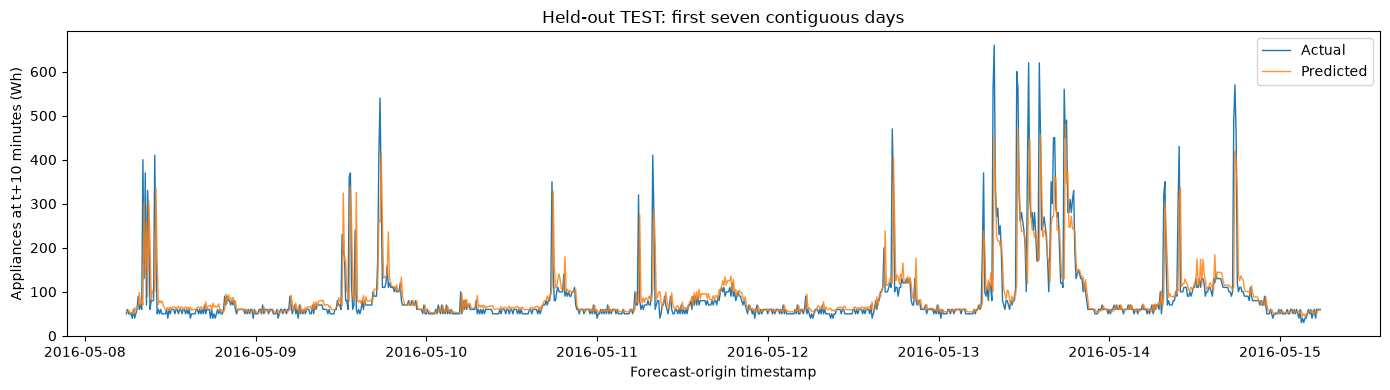

In [3]:
window = predictions.loc[predictions.date < predictions.date.iloc[0] + pd.Timedelta(days=7)]
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(window.date, window.actual, label='Actual', linewidth=1)
ax.plot(window.date, window.predicted, label='Predicted', linewidth=1, alpha=0.85)
ax.set(title='Held-out TEST: first seven contiguous days', xlabel='Forecast-origin timestamp', ylabel='Appliances at t+10 minutes (Wh)')
ax.legend()
fig.tight_layout()
generated = PROJECT_ROOT / 'ml/results/generated'
fig.savefig(generated / 'phase11_actual_vs_predicted.png', dpi=150)
plt.show()

## Residual diagnostics only

Residual = actual minus predicted. Positive residuals indicate underprediction. Standard deviation is the sample standard deviation (ddof=1). No test observations are removed or altered, and these diagnostics do not trigger tuning, feature selection or model replacement.

Mean residual: -1.0790800160468792
Sample residual standard deviation: 59.11768476871356
Median residual: -5.231040954589844


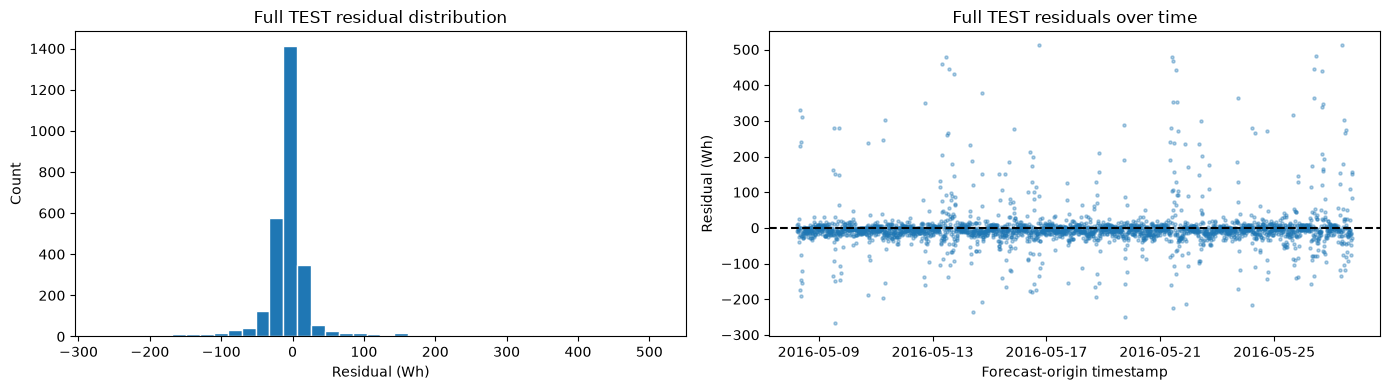

Exact technical replay: {'exact_metrics_reproduced': True, 'exact_predictions_reproduced': True, 'identical_configuration_inputs_dependencies': True, 'note': 'Identical technical replay only; no new selection or tuning decisions', 'original_result_sha256': '00af469b8ee4270ba85c92c77832e89929715acdfe802efe7df84dcb1ac534d9'}


In [4]:
print('Mean residual:', report['test_mean_residual'])
print('Sample residual standard deviation:', report['test_residual_std'])
print('Median residual:', report['test_median_residual'])
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(predictions.residual, bins=40, edgecolor='white')
axes[0].set(title='Full TEST residual distribution', xlabel='Residual (Wh)', ylabel='Count')
axes[1].scatter(predictions.date, predictions.residual, s=5, alpha=0.35)
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set(title='Full TEST residuals over time', xlabel='Forecast-origin timestamp', ylabel='Residual (Wh)')
fig.tight_layout()
fig.savefig(generated / 'phase11_residuals.png', dpi=150)
plt.show()
print('Exact technical replay:', read_json(REPLAY_PATH))
assert not report['post_test_tuning_performed']
assert not report['alternative_candidates_evaluated_on_test']
assert not report['model_artifact_saved']
assert report['input_checksums_unchanged']

## Limitations and fixed conclusion

These held-out estimates describe one later chronological period in a single observed building. Temporal dependence and seasonal distribution differences limit generalization; no confidence intervals are claimed. This is one-step-ahead forecasting with observed current values and valid historical context available at each origin, not recursive hourly or day-ahead forecasting. Existing Phase 6 partitions and approved features are preserved. No causal energy savings, occupancy or physical control conclusions follow.

The first valid held-out result remains final. The exact technical replay verifies identical data, configuration, dependencies, predictions and metrics, and is not another model-selection experiment. No post-test tuning, alternative-candidate test evaluation, model persistence or explainability is performed. Phase 11 ends here.